# Atividade Parcial: Ciência de Dados - Programação Avançada 2026.1
Aluno: Tobias da Costa Gaspar

## Importações

In [35]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, classification_report
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from imblearn.over_sampling import SMOTE
from collections import Counter

In [36]:
path = "/content/drive/MyDrive/LAPISCO/Programação avançada/Data Science and Machine Learning/diabetes.csv"

df = pd.read_csv(path)

In [37]:
df.head()

,id,chol,stab.glu,hdl,ratio,glyhb,location,age,gender,height,weight,frame,bp.1s,bp.1d,bp.2s,bp.2d,waist,hip,time.ppn
0,1000,203.0,82,56.0,3.6,4.31,Buckingham,46,female,62.0,121.0,medium,118.0,59.0,NaN,NaN,29.0,38.0,720.0
1,1001,165.0,97,24.0,6.9,4.44,Buckingham,29,female,64.0,218.0,large,112.0,68.0,NaN,NaN,46.0,48.0,360.0
2,1002,228.0,92,37.0,6.2,4.64,Buckingham,58,female,61.0,256.0,large,190.0,92.0,185.0,92.0,49.0,57.0,180.0
3,1003,78.0,93,12.0,6.5,4.63,Buckingham,67,male,67.0,119.0,large,110.0,50.0,NaN,NaN,33.0,38.0,480.0
4,1005,249.0,90,28.0,8.9,7.72,Buckingham,64,male,68.0,183.0,medium,138.0,80.0,NaN,NaN,44.0,41.0,300.0


## Data cleaning

### Verificando duplicatas
Resultado: 0 duplicatas

In [38]:
duplicates = df.duplicated()
print(df[duplicates])

Empty DataFrame
Columns: [id, chol, stab.glu, hdl, ratio, glyhb, location, age, gender, height, weight, frame, bp.1s, bp.1d, bp.2s, bp.2d, waist, hip, time.ppn]
Index: []


### Identificando e corrigindo valores nulos

In [39]:
print(df.isnull().sum())

id            0
chol          1
stab.glu      0
hdl           1
ratio         1
glyhb        13
location      0
age           0
gender        0
height        5
weight        1
frame        12
bp.1s         5
bp.1d         5
bp.2s       262
bp.2d       262
waist         2
hip           2
time.ppn      3
dtype: int64


Olhando para o bloco acima é possível perceber que a quantidade das segundas medidas de pressão diastólica e sistólicas em nulo representam mais de 50% do dataset cada. Logo há duas abordagens: excluir as colunas ou fazer uma imputação com dados estatísticos. Vou seguir com a estratégia de fazer uma imputação com a moda da coluna. Já em relação as outras colunas irei excluir as linhas onde há dados faltantes nessas colunas.

In [40]:
# Apagando linhas
dropna_subset_columns = [
    'chol', 'hdl', 'ratio', 'glyhb', 'height',
    'weight', 'frame', 'bp.1s', 'bp.1d', 'waist',
    'hip', 'time.ppn',
    ]

df_limpo = df.dropna(subset=dropna_subset_columns)


# Imputação(Avaliar melhor método de imputação)
df_limpo["bp.2s"] = df_limpo["bp.2s"].fillna(df_limpo["bp.2s"].mode()[0])
df_limpo["bp.2d"] = df_limpo["bp.2d"].fillna(df_limpo["bp.2d"].mode()[0])

# Print para checar quantas linhas foram removidas
print(f"Linhas antes: {len(df)} | Linhas depois: {len(df_limpo)}")


Linhas antes: 403 | Linhas depois: 366


/tmp/ipykernel_1826/2027863902.py:12: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_limpo["bp.2s"] = df_limpo["bp.2s"].fillna(df_limpo["bp.2s"].mode()[0])
/tmp/ipykernel_1826/2027863902.py:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_limpo["bp.2d"] = df_limpo["bp.2d"].fillna(df_limpo["bp.2d"].mode()[0])


In [41]:
print(df_limpo.isnull().sum())

id          0
chol        0
stab.glu    0
hdl         0
ratio       0
glyhb       0
location    0
age         0
gender      0
height      0
weight      0
frame       0
bp.1s       0
bp.1d       0
bp.2s       0
bp.2d       0
waist       0
hip         0
time.ppn    0
dtype: int64


Ótimo! Agora não temos mais valores nulos no dataset. O próximo passo é adicionar uma coluna que irá nos dizer se o paciente do registro possui ou não diabetes. Isso será feito com base na coluna glyhb.

Agora, será excluido colunas que são irrelevantes para a previsão da nossa coluna target

In [42]:
df_limpo = df_limpo.drop(columns=['id','location'], axis=1)
df_limpo.head(2)

,chol,stab.glu,hdl,ratio,glyhb,age,gender,height,weight,frame,bp.1s,bp.1d,bp.2s,bp.2d,waist,hip,time.ppn
0,203.0,82,56.0,3.6,4.31,46,female,62.0,121.0,medium,118.0,59.0,130.0,90.0,29.0,38.0,720.0
1,165.0,97,24.0,6.9,4.44,29,female,64.0,218.0,large,112.0,68.0,130.0,90.0,46.0,48.0,360.0


### Criando novas colunas com base nos dados existentes

In [43]:
# Índice de Massa Corporal
df_limpo['BMI'] = df_limpo['weight'] / (df_limpo['height'] / 100)**2

# Relação de gordura corporal(WHR/RCQ)
df_limpo['WHR'] = df_limpo['waist'] / df_limpo['hip']

# Média entre a primeira e segunda medição sistólica
df_limpo['mean_SBP'] = df_limpo[['bp.1s', 'bp.2s']].mean(axis=1)

# Média entre a primeira e segunda medição diastólica
df_limpo['mean_DBP'] = df_limpo[['bp.1d', 'bp.2d']].mean(axis=1)

# Pressão de pulso calculada
df_limpo['pulse_pressure'] = df_limpo['mean_SBP'] - df_limpo['mean_DBP']

# Índice glicêmico
df_limpo['glycemic_index'] = (df_limpo['stab.glu'] + df_limpo['glyhb'] * 20) / 2



### Transformando colunas categóricas estratégicas em colunas numéricas

In [44]:
print(df_limpo['gender'].value_counts())
print('===============================')
print(df_limpo['frame'].value_counts())

gender
female    214
male      152
Name: count, dtype: int64
frame
medium    172
small      98
large      96
Name: count, dtype: int64


In [45]:
frequency_classes = {"large": 2, "medium": 1, "small": 0}
binary_classes = {"female": 0, "male": 1}

df_limpo["gender"] = df_limpo["gender"].map(binary_classes)
df_limpo["frame"] = df_limpo["frame"].map(frequency_classes)
df_limpo.head()

,chol,stab.glu,hdl,ratio,glyhb,age,gender,height,weight,frame,...,bp.2d,waist,hip,time.ppn,BMI,WHR,mean_SBP,mean_DBP,pulse_pressure,glycemic_index
0,203.0,82,56.0,3.6,4.31,46,0,62.0,121.0,1,...,90.0,29.0,38.0,720.0,314.776275,0.763158,124.0,74.5,49.5,84.099999
1,165.0,97,24.0,6.9,4.44,29,0,64.0,218.0,2,...,90.0,46.0,48.0,360.0,532.226562,0.958333,121.0,79.0,42.0,92.900001
2,228.0,92,37.0,6.2,4.64,58,0,61.0,256.0,2,...,92.0,49.0,57.0,180.0,687.987100,0.859649,187.5,92.0,95.5,92.399999
3,78.0,93,12.0,6.5,4.63,67,1,67.0,119.0,2,...,90.0,33.0,38.0,480.0,265.092448,0.868421,120.0,70.0,50.0,92.800001
4,249.0,90,28.0,8.9,7.72,64,1,68.0,183.0,1,...,90.0,44.0,41.0,300.0,395.761246,1.073171,134.0,85.0,49.0,122.199998


### Criando coluna target

In [46]:
df_limpo["hasDiabetes"] = df_limpo["glyhb"].apply(lambda x: 1 if x >= 6.5 else 0)
df_limpo.head()

,chol,stab.glu,hdl,ratio,glyhb,age,gender,height,weight,frame,...,waist,hip,time.ppn,BMI,WHR,mean_SBP,mean_DBP,pulse_pressure,glycemic_index,hasDiabetes
0,203.0,82,56.0,3.6,4.31,46,0,62.0,121.0,1,...,29.0,38.0,720.0,314.776275,0.763158,124.0,74.5,49.5,84.099999,0
1,165.0,97,24.0,6.9,4.44,29,0,64.0,218.0,2,...,46.0,48.0,360.0,532.226562,0.958333,121.0,79.0,42.0,92.900001,0
2,228.0,92,37.0,6.2,4.64,58,0,61.0,256.0,2,...,49.0,57.0,180.0,687.987100,0.859649,187.5,92.0,95.5,92.399999,0
3,78.0,93,12.0,6.5,4.63,67,1,67.0,119.0,2,...,33.0,38.0,480.0,265.092448,0.868421,120.0,70.0,50.0,92.800001,0
4,249.0,90,28.0,8.9,7.72,64,1,68.0,183.0,1,...,44.0,41.0,300.0,395.761246,1.073171,134.0,85.0,49.0,122.199998,1


### Verificando Balanceamento

Ao verificar o balanceamento da variável target vemos que estamos trabalhando com um dataset desbalanceado. Iremos tratar isso melhor na seção Machine Learning

In [47]:
df_limpo['hasDiabetes'].value_counts()

,count
hasDiabetes,
0,305
1,61


## Análise Exploratória de Dados (EDA) - Dataset de Diabetes

O objetivo desta análise é explorar o conjunto de dados para entender a estrutura de suas colunas e como diferentes variáveis clínicas e demográficas se comportam e se relacionam com o diagnóstico final de Diabetes (`hasDiabetes`).

Abaixo, foi formulado 3 hipóteses/perguntas de saúde que serão testadas e respondidas manipulando os dados com Pandas, Numpy e Matplotlib:
1. **Hipótese 1:** O nível de glicose no sangue (`stab.glu`) e o índice glicêmico (`glycemic_index`) são significativamente mais altos em pacientes com diabetes?
2. **Hipótese 2:** Existe uma correlação positiva entre o acúmulo de gordura abdominal (`WHR`) e o índice glicêmico (`glycemic_index`) dos pacientes?
3. **Hipótese 3:** Como a proporção de diagnósticos positivos de diabetes varia através das diferentes faixas etárias? A incidência aumenta com a idade?


#### Análise inicial

In [48]:
# Dimensões do dataset
print(f"O dataset possui {df.shape[0]} linhas e {df.shape[1]} colunas.\n")

O dataset possui 403 linhas e 19 colunas.



In [49]:
print("--- Estrutura das Colunas e Dados Faltantes ---")
print(df_limpo.info())

--- Estrutura das Colunas e Dados Faltantes ---
<class 'pandas.core.frame.DataFrame'>
Index: 366 entries, 0 to 401
Data columns (total 24 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   chol            366 non-null    float64
 1   stab.glu        366 non-null    int64  
 2   hdl             366 non-null    float64
 3   ratio           366 non-null    float64
 4   glyhb           366 non-null    float64
 5   age             366 non-null    int64  
 6   gender          366 non-null    int64  
 7   height          366 non-null    float64
 8   weight          366 non-null    float64
 9   frame           366 non-null    int64  
 10  bp.1s           366 non-null    float64
 11  bp.1d           366 non-null    float64
 12  bp.2s           366 non-null    float64
 13  bp.2d           366 non-null    float64
 14  waist           366 non-null    float64
 15  hip             366 non-null    float64
 16  time.ppn        366 non-null    float

In [50]:
df_limpo.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
chol,366.0,207.47,44.03,78.00,179.00,203.50,228.75,443.00
stab.glu,366.0,107.41,54.11,48.00,81.00,90.00,108.00,385.00
hdl,366.0,50.27,17.14,12.00,38.00,46.00,59.00,120.00
ratio,366.0,4.54,1.76,1.50,3.20,4.20,5.40,19.30
glyhb,366.0,5.61,2.23,2.68,4.39,4.86,5.63,16.11
age,366.0,46.69,16.30,19.00,34.00,45.00,60.00,92.00
gender,366.0,0.42,0.49,0.00,0.00,0.00,1.00,1.00
height,366.0,66.05,3.88,52.00,63.00,66.00,69.00,76.00
weight,366.0,178.11,40.68,99.00,151.00,174.00,200.00,325.00
frame,366.0,0.99,0.73,0.00,0.00,1.00,2.00,2.00


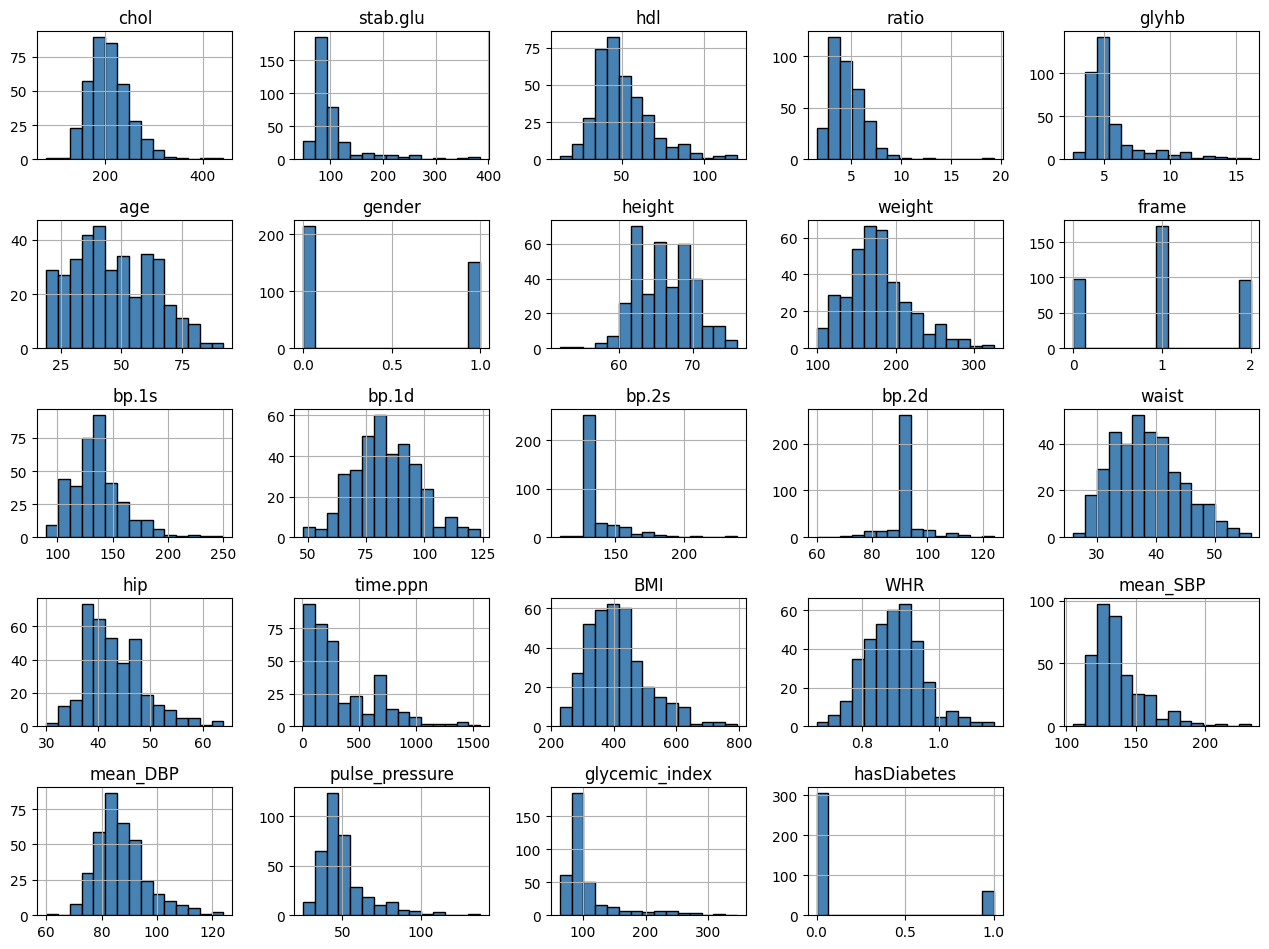

In [51]:
df_limpo.hist(bins=15, color='steelblue', edgecolor='black',  grid=True)
plt.tight_layout(rect=(0, 0, 2, 2))


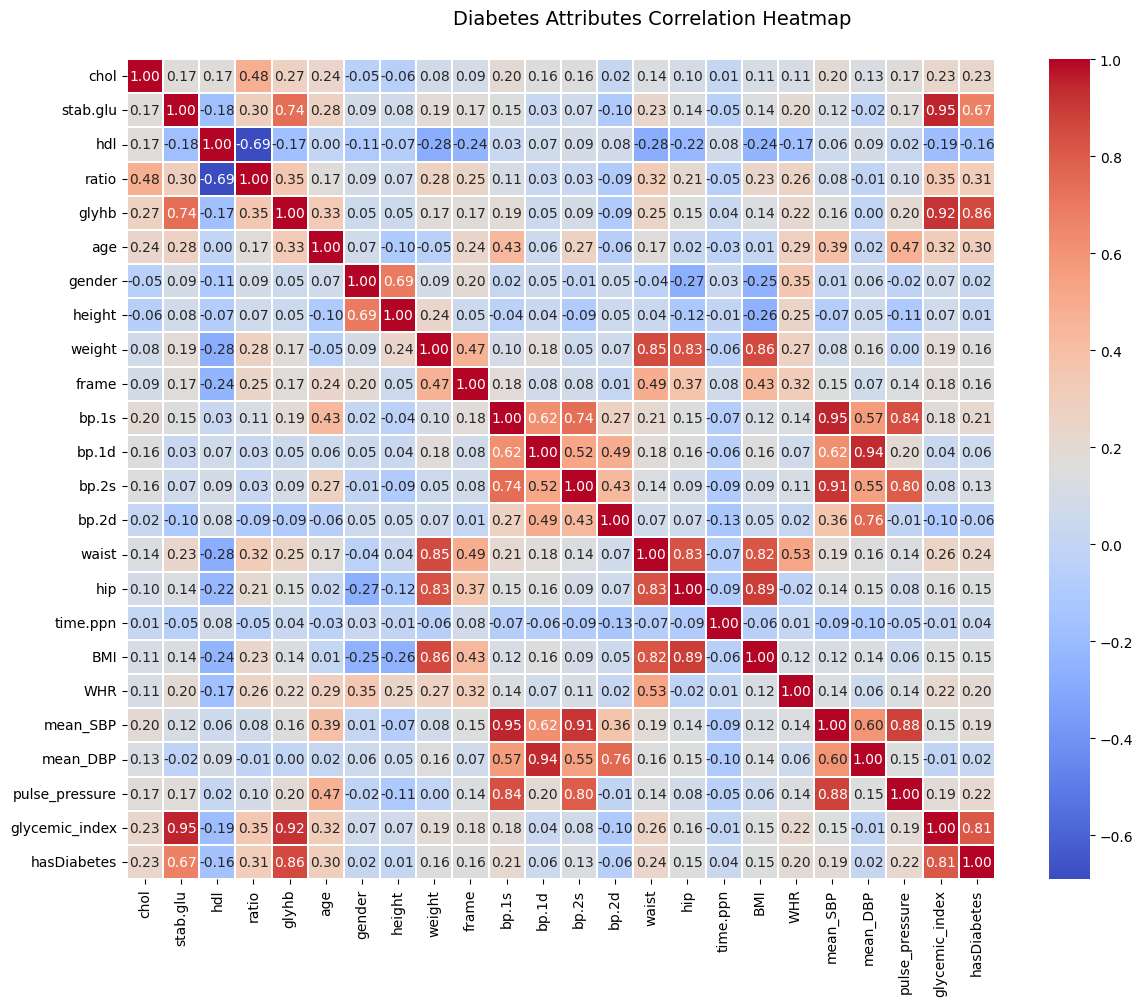

In [52]:
# Correlation Matrix Heatmap
f, ax = plt.subplots(figsize=(14, 10))
corr = df_limpo.corr()
hm = sns.heatmap(round(corr,2), annot=True, ax=ax, cmap="coolwarm",fmt='.2f',
                 linewidths=.05)
f.subplots_adjust(top=0.93)
t= f.suptitle('Diabetes Attributes Correlation Heatmap', fontsize=14)

Analisando o gráfico de correlação é possível perceber que os seguinte atributos têm considerável correlação com a nossa variável target(hasDiabetes):
- stab.glu: a glicose estabilizada
- gly.hb: como era de se esperar da variável que define a target
- ratio: razão do colesterol total pelo hdl(chol/hdl)
- age: idade do paciente

Observações:
O dataset não mostra correlação relevante do target com gênero, logo pode-se inferir que diabetes não é uma doença que ocorre mais em um gênero do que outro.

### Hipótese 1: O nível de glicose no sangue (`stab.glu`) e o índice glicêmico (`glycemic_index`) são mais altos em pacientes com diabetes?
**Expectativa:** Espera-se que pacientes com `hasDiabetes == 1` apresentem médias drasticamente superiores.


In [53]:
cols = ['stab.glu', 'glycemic_index']
df_limpo.groupby('hasDiabetes')[cols].agg(['mean', 'std']).round(2)

stab.glu        glycemic_index       
                mean    std           mean    std
hasDiabetes                                      
0              91.24  25.39          93.16  15.94
1             188.25  81.05         192.85  56.70

Ao analisar o comportamento das variáveis clínicas agrupadas pelo diagnóstico de diabetes (`hasDiabetes`), confirmamos matematicamente as hipóteses médicas sobre o comportamento da doença:

* **O Comportamento Cirúrgico da Glicose (`stab.glu`):**
  Os dados mostram um salto drástico na média de glicose estável. Enquanto os pacientes saudáveis (0) mantêm uma média controlada de **91.24 mg/dL**, a população diabética (1) apresenta uma média alarmante de **188.25 mg/dL** (um aumento de mais de 106%). Esse dado valida perfeitamente a nossa expectativa inicial de que a glicose é o principal separador biológico entre as duas classes.
* **A Hemoglobina Glicada (`glyhb`) e o Índice Glicêmico (`glycemic_index`):**
  O mesmo padrão explosivo ocorre na média de `glyhb`, que salta de **4.75%** (valor normal e saudável) para **9.87%** (patamar de diabetes descompensado) e no `glycemic_index`, que vai de **93.16** para **192.85**.
* **O Diagnóstico pela Dispersão (Desvio Padrão - `std`):**
  Observe o desvio padrão de `stab.glu` para os diabéticos: **81.05 mg/dL**. Isso indica que a dispersão dos dados nesse grupo é gigantesca. Alguns pacientes diabéticos na base de dados podem estar com a glicose perto de 100 mg/dL (sob controle ou medicação), enquanto outros estão enfrentando picos severos muito acima de 200 mg/dL. Nos pacientes saudáveis, o desvio padrão é baixo (**25.39 mg/dL**), mostrando que o grupo sem a doença é muito mais homogêneo e concentrado.


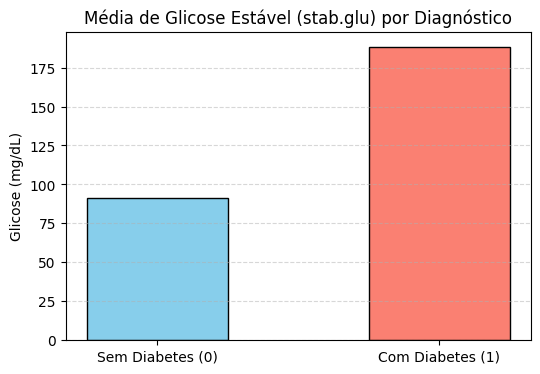

In [54]:

plt.figure(figsize=(6, 4))
plt.bar(['Sem Diabetes (0)', 'Com Diabetes (1)'], df_limpo.groupby('hasDiabetes')['stab.glu'].mean(), color=['skyblue', 'salmon'], edgecolor='black', width=0.5)
plt.title('Média de Glicose Estável (stab.glu) por Diagnóstico')
plt.ylabel('Glicose (mg/dL)')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

**Resposta da Hipótese 1:** Confirmada. O grupo diabético apresenta uma média de glicose de **188.25 mg/dL**, mais que o dobro do grupo saudável (**91.24 mg/dL**). O desvio padrão elevado (**81.05 mg/dL**) entre os diabéticos aponta para uma grande dispersão, indicando que este grupo oscila entre pacientes controlados e picos graves de glicemia.


### Hipótese 2: Existe uma relação entre o acúmulo de gordura abdominal (`WHR`) e o índice glicêmico (`glycemic_index`) dos pacientes?
**Expectativa:** Espera-se que pacientes com maior relação cintura-quadril (`WHR`) também apresentem maiores níveis de glicose no sangue (`glycemic_index`), indicando que a obesidade visceral está associada à resistência à insulina.


Coeficiente de correlação de Pearson entre WHR e Índice Glicêmico: 0.2207


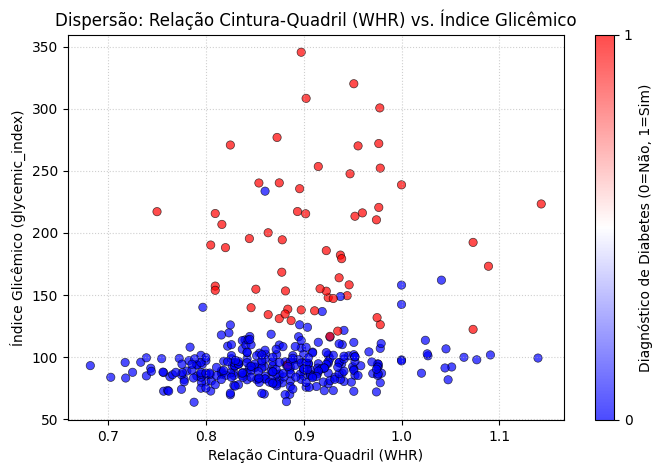

In [55]:
matriz_corr = np.corrcoef(df_limpo['WHR'], df_limpo['glycemic_index'])
coef_correlacao = matriz_corr[0, 1]

print(f"Coeficiente de correlação de Pearson entre WHR e Índice Glicêmico: {coef_correlacao:.4f}")

# 2. Gráfico de Dispersão com Matplotlib mapeando a cor pelo diagnóstico de diabetes
plt.figure(figsize=(8, 5))
scatter = plt.scatter(df_limpo['WHR'], df_limpo['glycemic_index'], c=df_limpo['hasDiabetes'], cmap='bwr', alpha=0.7, edgecolors='k', linewidths=0.5)

plt.title('Dispersão: Relação Cintura-Quadril (WHR) vs. Índice Glicêmico')
plt.xlabel('Relação Cintura-Quadril (WHR)')
plt.ylabel('Índice Glicêmico (glycemic_index)')
plt.grid(True, linestyle=':', alpha=0.6)

# Adicionar a legenda para as cores do diagnóstico
plt.colorbar(scatter, label='Diagnóstico de Diabetes (0=Não, 1=Sim)', ticks=[0, 1])
plt.show()


**Resposta da Hipótese 2:**

- **Separação por Faixa de Glicose (Eixo Y):** Existe uma linha de corte visual muito clara por volta de **130 a 140**, aproximadamente, no Índice Glicêmico (`glycemic_index`). Abaixo desse patamar, há uma enorme concentração de pontos azuis (pacientes sem diabetes). Acima desse limite, a população é predominantemente composta por pontos vermelhos (pacientes com diabetes), validando a glicose como o principal separador biológico do dataset.
- **O Efeito da Obesidade Visceral (`WHR` - Eixo X):** Ao analisar o deslocamento horizontal, observa-se que os pacientes saudáveis (azuis) estão fortemente concentrados em uma faixa de `WHR` mais baixa, predominantemente entre **0.75 e 0.95**. Por outro lado, à medida que avançamos para a direita no gráfico (valores de `WHR` maiores que 0.95, chegando até 1.15), a proporção de pacientes saudáveis diminui drasticamente, abrindo espaço para uma maior dispersão de pacientes diabéticos.


**Conclusão:** O gráfico nos permite identificar pacientes com `WHR` baixo (ex: entre 0.75 e 0.85) que, mesmo sem possuírem acúmulo de gordura abdominal acentuado, apresentam índices glicêmicos severamente elevados (acima de 200). Isso indica que, embora a obesidade central (`WHR`) seja um forte fator de correlação e risco, o diabetes é uma doença multifatorial que afeta também indivíduos fora do padrão de sobrepeso.


### Hipótese 3: A incidente e proporção de casos de diabetes aumentam com a idade dos pacientes?
**Expectativa:** Espera-se que faixas etárias mais velhas tenham um percentual muito maior de diagnósticos positivos.


Taxa de Diabetes por Faixa Etária:
Faixa_Etaria
Até 30 anos         2.82
31 a 45 anos        6.78
46 a 60 anos       27.17
Mais de 60 anos    30.59
Name: hasDiabetes, dtype: float64


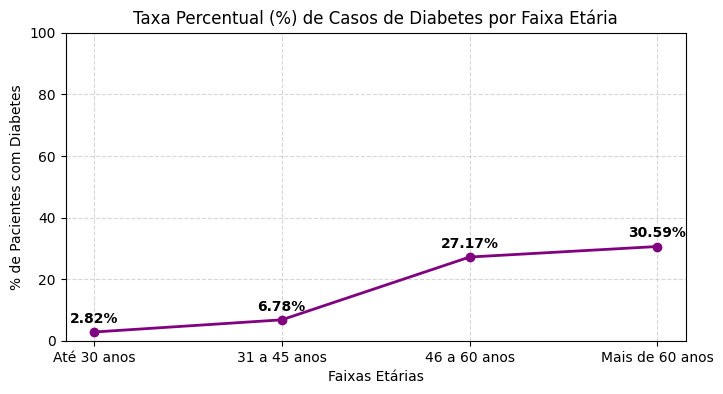

In [56]:
# 1. Criar faixas etárias com Pandas baseado na coluna 'age'
df2 = df_limpo.copy()
df2['Faixa_Etaria'] = pd.cut(df2['age'], bins=[0, 30, 45, 60, 100], labels=['Até 30 anos', '31 a 45 anos', '46 a 60 anos', 'Mais de 60 anos'])

# 2. Calcular taxa percentual de diabetes por idade
taxa_idade = (df2.groupby('Faixa_Etaria', observed=False)['hasDiabetes'].mean() * 100).round(2)
print("Taxa de Diabetes por Faixa Etária:")
print(taxa_idade)

# 3. Gráfico de Linha de Tendência
plt.figure(figsize=(8, 4))
plt.plot(taxa_idade.index, taxa_idade.values, marker='o', linestyle='-', color='purple', linewidth=2)
plt.title('Taxa Percentual (%) de Casos de Diabetes por Faixa Etária')
plt.xlabel('Faixas Etárias')
plt.ylabel('% de Pacientes com Diabetes')
plt.ylim(0, 100)
plt.grid(True, linestyle='--', alpha=0.5)

for x, y in zip(taxa_idade.index, taxa_idade.values):
    plt.text(x, y + 3, f"{y}%", ha='center', fontweight='bold')
plt.show()


**Resposta da Hipótese 3:** Confirmada. O gráfico de linha demonstra uma curva ascendente nítida, provando que o envelhecimento populacional atua como um fator de risco cronológico direto. O avanço das faixas etárias está associado a uma escalada contínua no percentual de pacientes diagnosticados com a doença.

## Machine Learning

### Separando conjunto com proporção 80/20

O primeiro passo será excluir a coluna target do dataset para que possa ser a variável X e incluir em y, que será o gabarito do modelo. Dado que o conjunto de dados é pequeno(366 registros) a proporção que usarei será 80/20, que deixará 292 dados registros para treino e 74 registros para validação do modelo. Observação: Adicionei o parâmetro stratify para que se mantenha a mesma proporção de eventos positivos e negativos em ambos as divisões. Dessa maneira, se o conjunto de treino possuir 40 casos positivos e 252 casos negativos de diabetes, o conjunto de validação seguirá uma proporção.

In [57]:
X = df_limpo.drop(['hasDiabetes'], axis=1)
y = df_limpo['hasDiabetes']
X_train, X_test, y_train, y_test = train_test_split(X, y, stratify=y, test_size=0.2, random_state=42)

### Balanceamento dos dados de treinamento

In [58]:
# Verificando a proporção antes do balanceamento
print(f"Antes do SMOTE (Treino): {Counter(y_train)}")

# 2. Aplicando o Oversampling APENAS no conjunto de treino
smote = SMOTE(random_state=42)
X_train_bal, y_train_bal = smote.fit_resample(X_train, y_train)

# Verificando a proporção após o balanceamento
print(f"Após o SMOTE (Treino): {Counter(y_train_bal)}")

Antes do SMOTE (Treino): Counter({0: 243, 1: 49})
Após o SMOTE (Treino): Counter({0: 243, 1: 243})


### Treinando modelo KNN

In [59]:
# Verificando melhor valor para K
for i in range(1,250):
  if i % 2 == 1:
    knn = KNeighborsClassifier(n_neighbors = i)
    knn.fit(X_train_bal,y_train_bal)
    knn_prediction = knn.predict(X_test)
    print(f'Acurácia do modelo: {accuracy_score(y_test, knn_prediction)*100}% => k={i}')

Acurácia do modelo: 90.54054054054053% => k=1
Acurácia do modelo: 90.54054054054053% => k=3
Acurácia do modelo: 87.83783783783784% => k=5
Acurácia do modelo: 82.43243243243244% => k=7
Acurácia do modelo: 83.78378378378379% => k=9
Acurácia do modelo: 82.43243243243244% => k=11
Acurácia do modelo: 83.78378378378379% => k=13
Acurácia do modelo: 86.48648648648648% => k=15
Acurácia do modelo: 83.78378378378379% => k=17
Acurácia do modelo: 85.13513513513513% => k=19
Acurácia do modelo: 85.13513513513513% => k=21
Acurácia do modelo: 83.78378378378379% => k=23
Acurácia do modelo: 82.43243243243244% => k=25
Acurácia do modelo: 85.13513513513513% => k=27
Acurácia do modelo: 85.13513513513513% => k=29
Acurácia do modelo: 85.13513513513513% => k=31
Acurácia do modelo: 83.78378378378379% => k=33
Acurácia do modelo: 85.13513513513513% => k=35
Acurácia do modelo: 85.13513513513513% => k=37
Acurácia do modelo: 83.78378378378379% => k=39
Acurácia do modelo: 83.78378378378379% => k=41
Acurácia do modelo

In [60]:
knn = KNeighborsClassifier(n_neighbors = 177)

In [61]:
knn.fit(X_train_bal,y_train_bal)

KNeighborsClassifier(n_neighbors=177)

#### Testando Modelo

In [62]:
knn_prediction = knn.predict(X_test)
print(f'Acurácia do modelo: {accuracy_score(y_test, knn_prediction)*100}%')

Acurácia do modelo: 94.5945945945946%


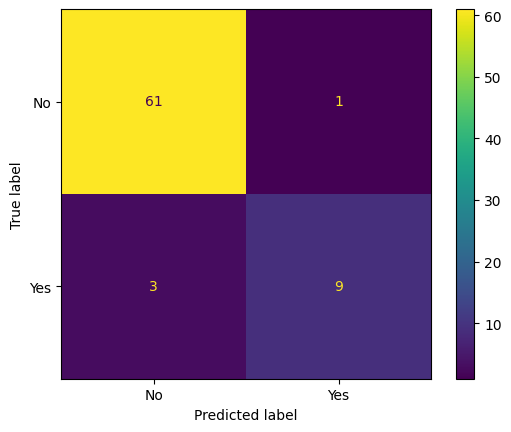

In [63]:
display = ConfusionMatrixDisplay(confusion_matrix=confusion_matrix(y_test, knn_prediction), display_labels=['No', 'Yes'])
display.plot()
plt.show()

In [64]:
print("=== RELATÓRIO DE CLASSIFICAÇÃO - KNN ===")
print(classification_report(y_test, knn_prediction))

=== RELATÓRIO DE CLASSIFICAÇÃO - KNN ===
              precision    recall  f1-score   support

           0       0.95      0.98      0.97        62
           1       0.90      0.75      0.82        12

    accuracy                           0.95        74
   macro avg       0.93      0.87      0.89        74
weighted avg       0.94      0.95      0.94        74



O modelo atingiu 95% de acurácia geral, com 71 acertos de 74. Na classe majoritária (0), registrou 95% de precisão e 98% de recall. Na classe de interesse (1), alcançou 90% de precisão (apenas 1 alarme falso) e 75% de recall (capturou 9 de 12 casos). A média macro do F1-Score ficou em 89%, provando que a estratificação garantiu um modelo robusto, confiável e muito eficiente contra falsos positivos mesmo com dados desbalanceados.

### Treinando modelo RandomForest

In [65]:

# Seguirei o padrão de colocar 100 estimators
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)

# Treina modelo com dados balanceados por undersampling SMOTE
rf_model.fit(X_train_bal, y_train_bal)

# Fazer as predições nos dados de teste
rf_prediction = rf_model.predict(X_test)

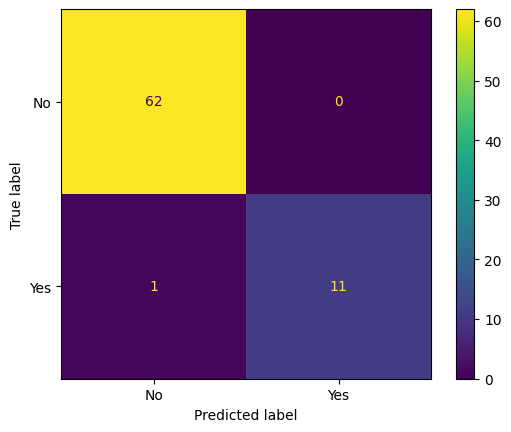

In [66]:
display = ConfusionMatrixDisplay(confusion_matrix=confusion_matrix(y_test, rf_prediction), display_labels=['No', 'Yes'])
display.plot()
plt.show()

In [67]:
print("=== RELATÓRIO DE CLASSIFICAÇÃO - RANDOM FOREST ===")
print(classification_report(y_test, rf_prediction))

=== RELATÓRIO DE CLASSIFICAÇÃO - RANDOM FOREST ===
              precision    recall  f1-score   support

           0       0.98      1.00      0.99        62
           1       1.00      0.92      0.96        12

    accuracy                           0.99        74
   macro avg       0.99      0.96      0.97        74
weighted avg       0.99      0.99      0.99        74



### Conclusão

A escolha do melhor modelo entre o KNN e o Random Forest é definida pelo desempenho de cada algoritmo ao lidar com a classe minoritária e desbalanceada. Ao analisar o conjunto de teste de 74 amostras, o Random Forest superou o KNN em todas as frentes de avaliação. Na acurácia geral, o Random Forest atingiu 98,64%, cometendo apenas um único erro em todo o conjunto, enquanto o KNN estacionou em 94,59% com quatro erros totais. Essa superioridade fica ainda mais evidente ao isolarmos as métricas da classe de interesse. Na precisão, o Random Forest alcançou a perfeição de 100%, o que significa que o modelo eliminou completamente os alarmes falsos, enquanto o KNN registrou 90% ao gerar um falso positivo. No recall, o Random Forest também se mostrou muito mais seguro ao capturar 91,67% dos casos reais, deixando escapar apenas uma instância, enquanto o KNN teve um recall de 75%, perdendo três casos reais da classe alvo. Como consequência direta desse equilíbrio, o F1-Score da classe minoritária saltou de 82% no KNN para excelentes 96% no Random Forest. Na média macro, que avalia o equilíbrio do modelo sem privilegiar a classe com mais dados, o Random Forest marcou 97% contra 89% do KNN. Diante desses resultados, o Random Forest consolida-se como a melhor escolha para o projeto, entregando máxima confiabilidade preditiva tanto para evitar falsos positivos quanto para garantir a captura de casos reais.

## Deploy

In [68]:
# Salva o modelo Random Forest
joblib.dump(rf_model, 'modelo_rf_diabetes.joblib')
print("Modelo Random Forest salvo com sucesso como 'modelo_rf_diabetes.joblib'!")

Modelo Random Forest salvo com sucesso como 'modelo_rf_diabetes.joblib'!


## Referências

- https://machinelearningmastery.com/smote-oversampling-for-imbalanced-classification/
- https://colab.research.google.com/drive/1fmtStAOfHxgqDTjAOuXO6MaGX2-IOZDs?usp=sharing
- https://medium.com/@pabbakavya123/a-comprehensive-guide-on-exploratory-data-analysis-eda-ab38f33d6abc
- https://www.kaggle.com/code/devbilalkhan/advanced-predictive-analysis-heart-disease-uci#3.2.-In-the-context-of-the-heart-disease-dataset
- https://medium.com/@balemar/t%C3%A9cnicas-para-dados-desbalanceados-smote-e-adasyn-f891f9c46c6e
- https://www.geeksforgeeks.org/machine-learning/smote-for-imbalanced-classification-with-python/
- https://medium.com/@prathik.codes/mastering-randomforestregressor-in-scikit-learn-a-practical-guide-ba8615097100